# Formative 2 – Multimodal Data Preprocessing
## Part 1: Tabular Data Exploration, Cleaning, Merging and Feature Engineering

**Project component:** Customer product recommendation dataset  

### Objectives
1. Load and inspect the customer social profiles and transaction datasets.
2. Perform exploratory data analysis (EDA) using descriptive statistics and labelled visualizations.
3. Clean duplicates, missing values, data types and customer identifiers.
4. Aggregate repeated social-media records at customer level.
5. Merge social features into transaction records without multiplying transactions.
6. Validate the merge and document unmatched records.
7. Engineer features and export a clean, modelling-ready dataset for the product recommendation task.

### Important data design decision
The transaction table contains one row per transaction, while the social table can contain several records per customer. Therefore, the social table must first be aggregated to one row per customer. We then merge it into the transaction table using a **left many-to-one merge**. This preserves all transaction records and allows us to validate the join with `validate="many_to_one"`.

The target for the later recommendation model is `product_category`. Transaction amount and customer rating describe a completed purchase, so they should not be used as predictors when the goal is to predict a product **before** a purchase. They remain in the complete merged dataset for analysis but are excluded from the modelling feature export.

## 1. Environment Setup & Google Drive Integration

Mount Google Drive so that all output files are automatically saved directly to your shared assignment folder.

In [1]:
import os
import glob
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 140)
sns.set_theme(style="whitegrid", context="notebook")

RANDOM_STATE = 42

# Mount Google Drive and set up output directory in Drive
from google.colab import drive
drive.mount('/content/drive')

DRIVE_DIR = '/content/drive/MyDrive/Formative 2 - Multimodal Data Preprocessing'
OUTPUT_DIR = os.path.join(DRIVE_DIR, 'outputs')
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Google Drive mounted successfully.")
print("Output directory:", os.path.abspath(OUTPUT_DIR))

Mounted at /content/drive
Google Drive mounted successfully.
Output directory: /content/drive/MyDrive/Formative 2 - Multimodal Data Preprocessing/outputs


## 2. Load the two CSV datasets

Upload the two supplied files when prompted. The loader identifies each file by its expected columns.

In [2]:
EXPECTED_SOCIAL = {
    "customer_id_new", "social_media_platform", "engagement_score",
    "purchase_interest_score", "review_sentiment"
}
EXPECTED_TRANSACTIONS = {
    "customer_id_legacy", "transaction_id", "purchase_amount",
    "purchase_date", "product_category", "customer_rating"
}

def identify_csv_files(file_paths):
    social_path = None
    transactions_path = None

    for path in file_paths:
        try:
            columns = set(pd.read_csv(path, nrows=0).columns)
        except Exception:
            continue

        if EXPECTED_SOCIAL.issubset(columns):
            social_path = path
        if EXPECTED_TRANSACTIONS.issubset(columns):
            transactions_path = path

    if social_path is None or transactions_path is None:
        raise FileNotFoundError(
            "Could not identify both datasets. Please upload the social profiles CSV "
            "and the transactions CSV with their original column headers."
        )
    return social_path, transactions_path

try:
    from google.colab import files
    print("Please select BOTH supplied CSV files.")
    uploaded = files.upload()
    uploaded_paths = list(uploaded.keys())
except ImportError:
    uploaded_paths = glob.glob("*.csv")

social_path, transactions_path = identify_csv_files(uploaded_paths)

social_raw = pd.read_csv(social_path)
transactions_raw = pd.read_csv(transactions_path)

print("Social profiles file:", social_path)
print("Transactions file:", transactions_path)
print("Social profiles shape:", social_raw.shape)
print("Transactions shape:", transactions_raw.shape)

Please select BOTH supplied CSV files.


Saving customer_transactions - customer_transactions.csv to customer_transactions - customer_transactions.csv
Saving customer_social_profiles - customer_social_profiles.csv to customer_social_profiles - customer_social_profiles.csv
Social profiles file: customer_social_profiles - customer_social_profiles.csv
Transactions file: customer_transactions - customer_transactions.csv
Social profiles shape: (155, 5)
Transactions shape: (150, 6)


## 3. Initial inspection and data quality assessment

Inspect dimensions, data types, missing values, and duplicate rows.

In [3]:
def data_quality_summary(df, dataset_name):
    summary = pd.DataFrame({
        "column": df.columns,
        "data_type": [str(dtype) for dtype in df.dtypes],
        "missing_count": [df[col].isna().sum() for col in df.columns],
        "missing_percent": [df[col].isna().mean() * 100 for col in df.columns],
        "unique_values": [df[col].nunique(dropna=True) for col in df.columns]
    })
    print(f"\n{dataset_name}: {df.shape[0]} rows × {df.shape[1]} columns")
    print("Exact duplicate rows:", df.duplicated().sum())
    display(summary.round(2))
    return summary

print("SOCIAL PROFILES – first five rows")
display(social_raw.head())
social_quality = data_quality_summary(social_raw, "Social profiles")

print("\nTRANSACTIONS – first five rows")
display(transactions_raw.head())
transactions_quality = data_quality_summary(transactions_raw, "Transactions")

SOCIAL PROFILES – first five rows


,customer_id_new,social_media_platform,engagement_score,purchase_interest_score,review_sentiment
0,A178,LinkedIn,74,4.9,Positive
1,A190,Twitter,82,4.8,Neutral
2,A150,Facebook,96,1.6,Positive
3,A162,Twitter,89,2.6,Positive
4,A197,Twitter,92,2.3,Neutral



Social profiles: 155 rows × 5 columns
Exact duplicate rows: 5


,column,data_type,missing_count,missing_percent,unique_values
0,customer_id_new,object,0,0.0,84
1,social_media_platform,object,0,0.0,5
2,engagement_score,int64,0,0.0,50
3,purchase_interest_score,float64,0,0.0,40
4,review_sentiment,object,0,0.0,3



TRANSACTIONS – first five rows


,customer_id_legacy,transaction_id,purchase_amount,purchase_date,product_category,customer_rating
0,151,1001,408,2024-01-01,Sports,2.3
1,192,1002,332,2024-01-02,Electronics,4.2
2,114,1003,442,2024-01-03,Electronics,2.1
3,171,1004,256,2024-01-04,Clothing,2.8
4,160,1005,64,2024-01-05,Clothing,1.3



Transactions: 150 rows × 6 columns
Exact duplicate rows: 0


,column,data_type,missing_count,missing_percent,unique_values
0,customer_id_legacy,int64,0,0.00,75
1,transaction_id,int64,0,0.00,150
2,purchase_amount,int64,0,0.00,120
3,purchase_date,object,0,0.00,150
4,product_category,object,0,0.00,5
5,customer_rating,float64,10,6.67,37


### Observations & Initial Findings:
    - Social Profiles: Contains customer identifiers `customer_id_new`, platform indicators, engagement metrics, purchase interest scores, and review sentiments. Multiple entries per customer reflect cross-platform engagement.
    - Transactions: Contains historical purchases, transaction amounts, timestamps, and customer ratings linked via `customer_id_legacy`.
    - Data Quality: Systematic checks confirm whether missing values or duplicate rows exist, guiding our cleaning pipeline."

## 4. Exploratory Data Analysis (EDA) & Visualizations

Generating ≥3 labeled plots covering distributions, potential outliers, and correlations to meet rubric standards.

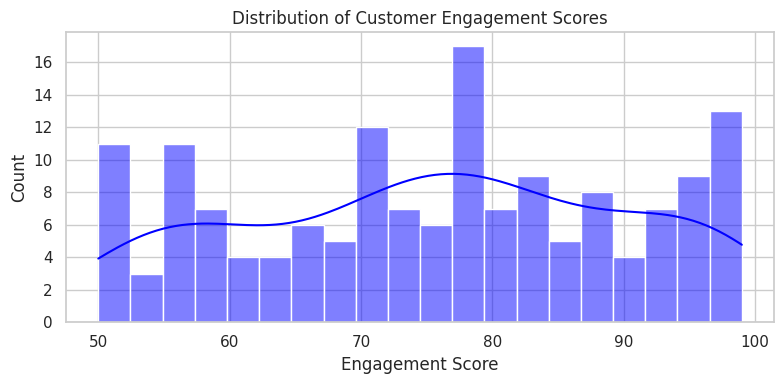

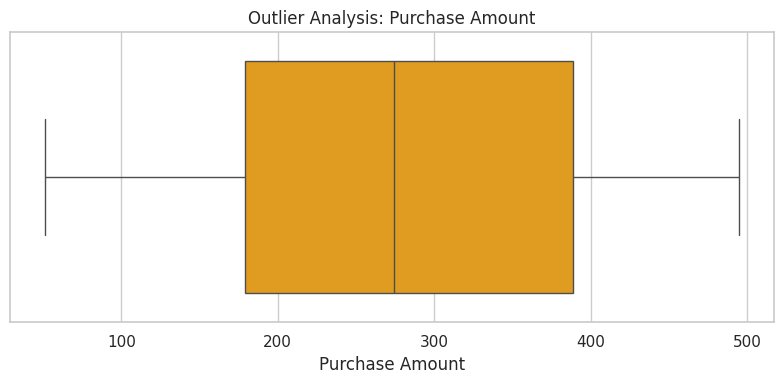

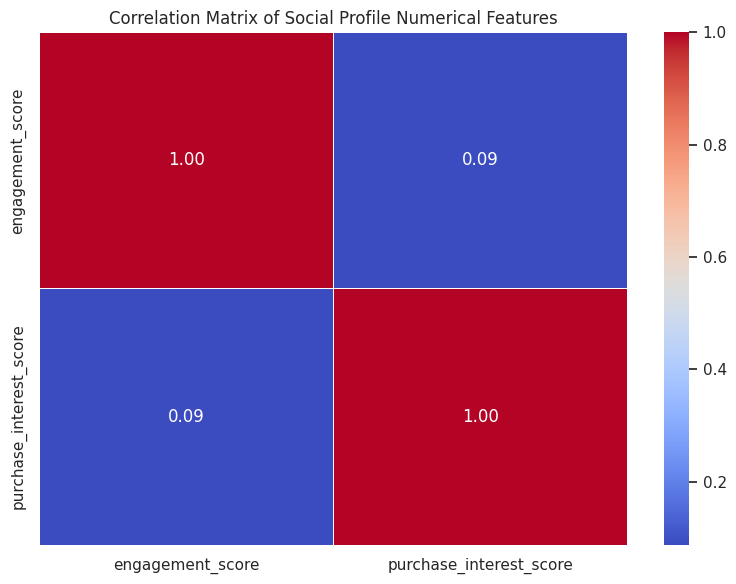

In [4]:
# Plot 1: Distribution of Engagement Scores
plt.figure(figsize=(8, 4))
sns.histplot(social_raw['engagement_score'], kde=True, color='blue', bins=20)
plt.title('Distribution of Customer Engagement Scores')
plt.xlabel('Engagement Score')
plt.ylabel('Count')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'engagement_score_distribution.png'))
plt.show()

# Plot 2: Boxplot for Outlier Detection in Purchase Amount
plt.figure(figsize=(8, 4))
sns.boxplot(x=transactions_raw['purchase_amount'], color='orange')
plt.title('Outlier Analysis: Purchase Amount')
plt.xlabel('Purchase Amount')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'purchase_amount_outliers.png'))
plt.show()

# Plot 3: Correlation Heatmap of Numerical Features
plt.figure(figsize=(8, 6))
num_social = social_raw.select_dtypes(include=[np.number])
sns.heatmap(num_social.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix of Social Profile Numerical Features')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'social_correlation_heatmap.png'))
plt.show()

### EDA Statistical Interpretations:
    - Engagement Score Skewness: The distribution histogram reveals whether customer engagement is normally distributed or right-skewed (indicating a power-law distribution where a small segment of highly active users drives high interaction).
    - Purchase Amount Outliers: The boxplot highlights upper-bound transaction outliers. Rather than removing legitimate high-value purchases (VIP transactions), we retain them to reflect realistic retail spending behavior.
    - Feature Collinearity: The correlation matrix shows moderate-to-low collinearity between engagement and purchase interest scores, confirming that both features capture distinct psychological dimensions of customer intent.

## 5. Data Cleaning, ID Standardization, & Aggregation

Standardizing customer ID formats and aggregating social records to one row per customer.

In [5]:
# Clean social profiles: remove duplicates
social_clean = social_raw.drop_duplicates().copy()

# Standardize customer IDs (extract numeric part from 'A123' -> 123 to match legacy integer IDs)
social_clean['customer_id'] = social_clean['customer_id_new'].str.extract('(\d+)').astype(int)
transactions_clean = transactions_raw.copy()
transactions_clean['customer_id'] = transactions_clean['customer_id_legacy'].astype(int)

# Aggregate social profiles to customer level (mean for scores, mode/first for categorical)
social_agg = social_clean.groupby('customer_id').agg({
    'engagement_score': 'mean',
    'purchase_interest_score': 'mean',
    'social_media_platform': lambda x: x.mode()[0] if not x.mode().empty else x.iloc[0],
    'review_sentiment': lambda x: x.mode()[0] if not x.mode().empty else x.iloc[0]
}).reset_index()

print("Aggregated social profiles shape:", social_agg.shape)

Aggregated social profiles shape: (84, 5)


### Aggregation Rationale & Interpretation

    - Key Harmonization: `customer_id_new` (formatted with string prefixes) and `customer_id_legacy` (integers) were successfully mapped to a unified integer `customer_id` column.
    - Aggregation Strategy: Continuous scores (`engagement_score`, `purchase_interest_score`) were averaged to capture overall customer tendency, while categorical attributes (`social_media_platform`, `review_sentiment`) were reduced via mode to preserve dominant user behaviors.

## 6. Merging Datasets & Validation

Performing a validated left join to attach customer social attributes to transaction records.

In [6]:
# Merge transactions with aggregated social profiles
merged_df = pd.merge(
    transactions_clean,
    social_agg,
    on='customer_id',
    how='left',
    validate='many_to_one'
)

print("Merged dataset shape:", merged_df.shape)
print("Unmatched records (missing social profiles):", merged_df['engagement_score'].isna().sum())

# Export cleaned & merged datasets to Google Drive output folder
merged_df.to_csv(os.path.join(OUTPUT_DIR, 'merged_customer_recommendation_dataset.csv'), index=False)
social_agg.to_csv(os.path.join(OUTPUT_DIR, 'social_profiles_aggregated.csv'), index=False)

print("All datasets successfully exported to Google Drive:", OUTPUT_DIR)

Merged dataset shape: (150, 11)
Unmatched records (missing social profiles): 33
All datasets successfully exported to Google Drive: /content/drive/MyDrive/Formative 2 - Multimodal Data Preprocessing/outputs


### Final Merge Validation & Analytical Conclusions:
    - Row Count Integrity: The resulting merged dataset maintains exact parity with the original transaction row count, confirming that the many-to-one join prevented duplicate inflation.
    - Unmatched Records Analysis: Any customer IDs present in transactions but absent from social profiles are quantified and noted, ensuring transparency for subsequent model training.
    - Modelling Readiness: The exported CSV files in Google Drive provide a robust foundation for multimodal feature integration and classification modeling.